# Evaluación Formativa 2: Práctica Guiada de Modelamiento Predictivo
**MCDI501: Estadística Computacional para la Toma de Decisiones**  
*Magíster en Ciencia de Datos e Inteligencia Artificial — Universidad Andrés Bello (UNAB)*  
**Grupo 6:** Fernanda Ovalle Román, Sebastián Cajales Cid, César Lorca Bacián, Jorge Álvarez Ossandón  
**Docente:** Jean Paul Maidana González | **Revisión metodológica:** DR  
**Fecha de Entrega:** Octubre 2026

---

### Resumen de la Actividad y Mejoras Metodológicas Integradas
Este cuaderno desarrolla el flujo completo de modelamiento supervisado para clasificar el atraso alto en la titulación universitaria chilena, incorporando las correcciones metodológicas de la retroalimentación docente:
1. **Cálculo Exógeno de Predictores:** Eliminación definitiva de la fuga de datos (*data leakage*) en `edad_ingreso`, calculada a partir de registros calendáricos sin restar la variable objetivo (`atraso_semestres`).
2. **Categoría de Referencia Explícita:** Fijación formal de categorías base (*Administración y Comercio*, *Hombre*, *A Distancia*) evitando la singularidad de la matriz de diseño.
3. **Experimento Controlado de Imputación en Predictor:** Como en los datos reales la ausencia en año de ingreso determina el objetivo, se induce un 12,75 % de faltantes en un predictor para comparar empíricamente eliminación, mediana y regresión lineal múltiple frente al *ground truth*.
4. **Tres Especificaciones Logísticas:** Contraste formal entre Modelo Base (S1/S2), Modelo Stepwise (AIC) y Modelo Reducido.
5. **Diagnóstico VIF sin Trampa de Indicadoras:** Evaluación de colinealidad sin la inflación espuria de dummies continuas ($VIF < 2,5$).
6. **Ponderación de Clases (Peso $\approx 2,04$):** Corrección del recall basal del modelo no ponderado ($8,89\,\%$, $AUC = 0,664$) ante el desbalance de clases ($24,54\,\%$ de atraso alto).
7. **Inferencia Robusta con Bootstrap ($B=1.000$):** Estimación de intervalos de confianza empíricos para los Odds Ratios.

## 1. Configuración del Entorno y Preparación de Datos

In [1]:
import os
import sys
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import (
    confusion_matrix, classification_report, roc_curve, roc_auc_score,
    accuracy_score, precision_score, recall_score, f1_score, brier_score_loss
)

# Configuración estética reproducible
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 110
pd.set_option('display.float_format', lambda x: f'{x:.4f}')
print('Entorno computacional cargado correctamente.')

Entorno computacional cargado correctamente.


### 1.1 Carga del Conjunto de Datos y Trazabilidad con S1 y S2

Se carga la base oficial de Titulados en Educación Superior 2025 (SIES, Mineduc) filtrando a **Pregrado Universitario** ($N = 105.063$). Se integran los hallazgos previos:
* **Sumativa 1:** Se diagnosticaron 13.396 casos con códigos centinela (`1900` y `0`) en fecha de ingreso original (12,75 % de nulos). El atraso típico fue de 2 semestres con fuerte asimetría positiva y 3.201 outliers de Tukey.
* **Sumativa 2:** Se demostró mediante pruebas de permutación que el área curricular modera la brecha de género y se validó mediante Bootstrap BCa ($B=10.000$) la estabilidad de la correlación de la edad ($ho = 0,466$).
* **Corrección de Endogeneidad:** En versiones preliminares, `edad_ingreso` se calculaba restando la mitad de `semestres_reales`, lo cual introducía parte del atraso (variable objetivo) dentro del predictor. En esta versión corregida, `edad_ingreso` se define de manera estrictamente exógena mediante años calendáricos: `anio_ing_carr_act - anio_nac`.

In [2]:
def cargar_datos_titulados():
    candidatos = [
        Path('data/raw/20260817_Titulados_Ed_Superior_2025_WEB.csv'),
        Path('../data/raw/20260817_Titulados_Ed_Superior_2025_WEB.csv'),
        Path('../../2_PROYECTO_GRUPAL_GIT/data/raw/20260817_Titulados_Ed_Superior_2025_WEB.csv'),
        Path('/home/scajales/Documentos/UNAB sebastian cajales/[MCDI500] Programación para la Ciencia de Datos/proyecto-grupo6-mcdi500/data/raw/20260817_Titulados_Ed_Superior_2025_WEB.csv')
    ]
    ruta = next((p for p in candidatos if p.exists()), None)
    if ruta is None:
        raise FileNotFoundError('No se encontró el archivo crudo de Titulados 2025.')
    print(f'Cargando base oficial desde: {ruta.resolve()}')
    
    crudo = pd.read_csv(ruta, sep=';', encoding='latin-1', low_memory=False)
    
    # Filtro oficial de Pregrado Universitario (S1)
    df = crudo[(crudo['nivel_global'] == 'Pregrado') & (crudo['tipo_inst_1'] == 'Universidades')].copy()
    
    # Variables temporales e indicadoras de centinelas
    df['anio_ing_carr_ori'] = df['anio_ing_carr_ori'].replace(1900, np.nan)
    df['sem_ing_carr_ori'] = df['sem_ing_carr_ori'].replace(0, np.nan)
    
    anio_tit = df['fecha_obtencion_titulo'] // 10000
    mes_tit = (df['fecha_obtencion_titulo'] // 100) % 100
    sem_tit = np.where(mes_tit <= 6, 1, 2)
    idx_titulo = anio_tit * 2 + (sem_tit - 1)
    
    idx_ori = df['anio_ing_carr_ori'] * 2 + (df['sem_ing_carr_ori'] - 1)
    df['semestres_reales'] = idx_titulo - idx_ori + 1
    
    anio_nac = df['fec_nac_alu'] // 100
    mes_nac = df['fec_nac_alu'] % 100
    df['edad_titulacion'] = ((anio_tit * 12 + mes_tit) - (anio_nac * 12 + mes_nac)) / 12.0
    
    # Variable objetivo: atraso alto (> 4 semestres, definido en S1)
    df['atraso_semestres'] = df['semestres_reales'] - df['dur_total_carr']
    df['atraso_alto'] = (df['atraso_semestres'] > 4).astype(float)
    df.loc[df['atraso_semestres'].isna(), 'atraso_alto'] = np.nan
    
    df['sexo'] = df['gen_alu'].map({1: 'Hombre', 2: 'Mujer'})
    
    # CORRECCION METODOLOGICA DR: edad de ingreso exogena
    df['edad_ingreso'] = df['anio_ing_carr_act'] - anio_nac
    
    return df.reset_index(drop=True)

df_total = cargar_datos_titulados()
n_tot = len(df_total)
n_obs = df_total['atraso_semestres'].notna().sum()
n_falt = df_total['atraso_semestres'].isna().sum()
pct_falt = (n_falt / n_tot) * 100

print(f'Total pregrado universitario: {n_tot:,} registros.')
print(f'Casos con atraso observado:   {n_obs:,} ({100-pct_falt:.2f} %).')
print(f'Casos con ingreso no obs.   : {n_falt:,} ({pct_falt:.2f} %).')

Cargando base oficial desde: /home/scajales/Documentos/UNAB sebastian cajales/[MCDI500] Programación para la Ciencia de Datos/proyecto-grupo6-mcdi500/data/raw/20260817_Titulados_Ed_Superior_2025_WEB.csv


Total pregrado universitario: 105,063 registros.
Casos con atraso observado:   91,667 (87.25 %).
Casos con ingreso no obs.   : 13,396 (12.75 %).


### 1.2 Experimento Metodológico: Inducción Controlada de Faltantes en un Predictor

> **Observación metodológica de DR:** En el conjunto de datos empírico, la no-observación en `anio_ing_carr_ori` define directamente la variable objetivo (`atraso_semestres`). Imputar el objetivo de forma no supervisada antes de entrenar un modelo predictivo altera artificialmente las etiquetas. Por ello, para evaluar de forma científicamente rigurosa las tres estrategias de manejo de datos faltantes que exige la pauta (**eliminación, mediana y regresión lineal múltiple**), se induce una pérdida controlada del **12,75 %** (equivalente a la tasa empírica) sobre el predictor continuo `edad_ingreso`, donde sí conocemos el valor real (*ground truth*).

In [3]:
# Subconjunto con atraso observado para modelamiento inicial (Complete-case en Y)
df_analisis = df_total.dropna(subset=['atraso_alto', 'edad_ingreso']).reset_index(drop=True)
df_analisis['atraso_alto'] = df_analisis['atraso_alto'].astype(int)

# Inducción controlada de faltantes en edad_ingreso (12,75 %)
rng_exp = np.random.default_rng(42)
n_exp = len(df_analisis)
n_falt_inducidos = int(n_exp * 0.1275)
mask_falt_exp = np.zeros(n_exp, dtype=bool)
mask_falt_exp[rng_exp.choice(n_exp, size=n_falt_inducidos, replace=False)] = True

y_verdadero = df_analisis.loc[mask_falt_exp, 'edad_ingreso'].values

# 1. Estrategia Mediana
mediana_obs = df_analisis.loc[~mask_falt_exp, 'edad_ingreso'].median()
y_pred_med = np.full(n_falt_inducidos, mediana_obs)
mae_med = float(np.mean(np.abs(y_verdadero - y_pred_med)))
rmse_med = float(np.sqrt(np.mean((y_verdadero - y_pred_med)**2)))

# 2. Estrategia Regresión Lineal Múltiple con covariables observadas
covars_imp = pd.get_dummies(df_analisis[['sexo', 'area_conocimiento', 'jornada', 'dur_total_carr']], drop_first=True, dtype=float)
covars_imp['dur_total_carr'] = covars_imp['dur_total_carr'].fillna(covars_imp['dur_total_carr'].median())

X_tr_imp = covars_imp.iloc[~mask_falt_exp]
y_tr_imp = df_analisis.loc[~mask_falt_exp, 'edad_ingreso'].values
X_te_imp = covars_imp.iloc[mask_falt_exp]

modelo_imp = LinearRegression().fit(X_tr_imp, y_tr_imp)
y_pred_reg = modelo_imp.predict(X_te_imp)
mae_reg = float(np.mean(np.abs(y_verdadero - y_pred_reg)))
rmse_reg = float(np.sqrt(np.mean((y_verdadero - y_pred_reg)**2)))
r2_imp = float(modelo_imp.score(X_tr_imp, y_tr_imp))

tabla_exp_faltantes = pd.DataFrame({
    'Estrategia de Imputación': [
        'Eliminación (Complete-Case)',
        'Imputación Simple (Mediana)',
        'Imputación por Regresión Múltiple'
    ],
    'Casos Utilizados / Imputados': [
        f'{n_exp - n_falt_inducidos:,} (descarta {n_falt_inducidos:,})',
        f'{n_exp:,} ({n_falt_inducidos:,} imputados)',
        f'{n_exp:,} ({n_falt_inducidos:,} imputados)'
    ],
    'MAE (Años)': ['N/A (descarta casos)', f'{mae_med:.3f}', f'{mae_reg:.3f}'],
    'RMSE (Años)': ['N/A (descarta casos)', f'{rmse_med:.3f}', f'{rmse_reg:.3f}'],
    'Evaluación Metodológica': [
        'Pierde 12,75 % de muestra; sesga estimadores si la pérdida es MAR.',
        'Colapsa la varianza e ignora la heterogeneidad por jornada y área.',
        f'Reduce RMSE en {(1 - rmse_reg/rmse_med)*100:.1f} % frente a mediana (R² = {r2_imp:.3f}).'
    ]
})
display(tabla_exp_faltantes)

,Estrategia de Imputación,Casos Utilizados / Imputados,MAE (Años),RMSE (Años),Evaluación Metodológica
0,Eliminación (Complete-Case),"79,980 (descarta 11,687)",N/A (descarta casos),N/A (descarta casos),"Pierde 12,75 % de muestra; sesga estimadores s..."
1,Imputación Simple (Mediana),"91,667 (11,687 imputados)",2.728,5.604,Colapsa la varianza e ignora la heterogeneidad...
2,Imputación por Regresión Múltiple,"91,667 (11,687 imputados)",2.349,4.123,Reduce RMSE en 26.4 % frente a mediana (R² = 0...


### 1.3 Selección de Predictores, Partición 70/30 Estratificada y Estandarización

Se seleccionan cuatro predictores fundamentales justificados en S1 y S2:
1. `sexo` (categórica binaria: brecha favorable a mujeres en titulación oportuna).
2. `edad_ingreso` (numérica continua: correlación positiva robusta $ho = 0,466$ validada por Bootstrap).
3. `jornada` (categórica: mayor tasa de atraso alto en jornada vespertina).
4. `area_conocimiento` (categórica: moderador estructural demostrado en prueba de permutación de S2).

**Categorías de referencia explícitas:** Para evitar la trampa de las variables ficticias (*dummy variable trap*) y garantizar la invertibilidad de la matriz de diseño, se utiliza `drop_first=True`, fijando como categorías base:
* **Sexo:** *Hombre*
* **Jornada:** *A Distancia*
* **Área de Conocimiento:** *Administración y Comercio*

In [4]:
# Dummies con referencia explícita garantizada mediante drop_first=True
X_categoricas = pd.get_dummies(
    df_analisis[['sexo', 'jornada', 'area_conocimiento']],
    drop_first=True,
    dtype=float
)

X_completa = pd.concat([df_analisis[['edad_ingreso']], X_categoricas], axis=1)
y_completa = df_analisis['atraso_alto']

# Partición 70/30 estratificada con semilla 42
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_completa, y_completa,
    test_size=0.30,
    random_state=42,
    stratify=y_completa
)

# Estandarización de la variable continua fitteada en train
scaler = StandardScaler()
X_train = X_train_raw.copy()
X_test = X_test_raw.copy()
X_train['edad_ingreso'] = scaler.fit_transform(X_train_raw[['edad_ingreso']])
X_test['edad_ingreso'] = scaler.transform(X_test_raw[['edad_ingreso']])

print(f'Muestra de Entrenamiento (70 %): {len(X_train):,} casos.')
print(f'Muestra de Prueba        (30 %): {len(X_test):,} casos.')
print(f'Tasa Atraso Alto en Train:       {y_train.mean()*100:.2f} %')
print(f'Tasa Atraso Alto en Test :       {y_test.mean()*100:.2f} %')
print('\nVariables predictoras listas (15 dummies + 1 continua):')
print(list(X_train.columns))

Muestra de Entrenamiento (70 %): 64,166 casos.
Muestra de Prueba        (30 %): 27,501 casos.
Tasa Atraso Alto en Train:       24.54 %
Tasa Atraso Alto en Test :       24.54 %

Variables predictoras listas (15 dummies + 1 continua):
['edad_ingreso', 'sexo_Mujer', 'jornada_Diurna', 'jornada_Otra', 'jornada_Semipresencial', 'jornada_Vespertina', 'area_conocimiento_Agropecuaria', 'area_conocimiento_Arte y Arquitectura', 'area_conocimiento_Ciencias BÃ¡sicas', 'area_conocimiento_Ciencias Sociales', 'area_conocimiento_Derecho', 'area_conocimiento_EducaciÃ³n', 'area_conocimiento_Humanidades', 'area_conocimiento_Salud', 'area_conocimiento_TecnologÃ\xada']


## 2. Modelos de Regresión Logística y Diagnóstico de Colinealidad

Siguiendo la indicación del profesor DR, se ajustan y comparan **tres especificaciones de regresión logística**:
1. **Modelo 1 (M1 · Base / Teórico):** Contiene la especificación completa fundamentada en S1 y S2 (`edad_ingreso`, `sexo`, `jornada` y `area_conocimiento`).
2. **Modelo 2 (M2 · Stepwise por AIC):** Procedimiento de selección por pasos hacia adelante evaluando la variable completa (todas sus dummies agrupadas) mediante la minimización del Criterio de Información de Akaike.
3. **Modelo 3 (M3 · Reducido / Parsimonioso):** Modelo compacto que retiene los predictores de mayor efecto (`edad_ingreso`, `sexo` y `jornada`) omitiendo la segmentación detallada de áreas.

In [5]:
# Matrices de diseño con intercepto para statsmodels
X_train_sm = sm.add_constant(X_train)
X_test_sm = sm.add_constant(X_test)

# Modelo 1: Teórico Completo
m1 = sm.Logit(y_train, X_train_sm).fit(disp=False)

# Modelo 3: Reducido (sin áreas de conocimiento)
cols_m3 = ['const', 'edad_ingreso', 'sexo_Mujer', 'jornada_Diurna', 'jornada_Otra', 'jornada_Semipresencial', 'jornada_Vespertina']
cols_m3 = [c for c in cols_m3 if c in X_train_sm.columns]
m3 = sm.Logit(y_train, X_train_sm[cols_m3]).fit(disp=False)

# Procedimiento Stepwise por variable completa según AIC
def stepwise_seleccion(X_base, y_base, bloques):
    seleccionados = []
    aic_actual = sm.Logit(y_base, sm.add_constant(pd.DataFrame(index=X_base.index))).fit(disp=False).aic
    while True:
        mejor_mejora = 0
        mejor_candidato = None
        mejor_aic = aic_actual
        for cand, cols in bloques.items():
            if cand not in seleccionados:
                cols_prueba = ['const']
                for s in seleccionados:
                    cols_prueba.extend(bloques[s])
                cols_prueba.extend(cols)
                ajuste_cand = sm.Logit(y_base, X_base[cols_prueba]).fit(disp=False)
                if ajuste_cand.aic < mejor_aic:
                    mejor_aic = ajuste_cand.aic
                    mejor_candidato = cand
        if mejor_candidato is not None and (aic_actual - mejor_aic) > 2.0:
            seleccionados.append(mejor_candidato)
            aic_actual = mejor_aic
        else:
            break
    return seleccionados, aic_actual

bloques_vars = {
    'edad_ingreso': ['edad_ingreso'],
    'sexo': ['sexo_Mujer'],
    'jornada': [c for c in X_train.columns if c.startswith('jornada_')],
    'area_conocimiento': [c for c in X_train.columns if c.startswith('area_conocimiento_')]
}

vars_step, aic_step = stepwise_seleccion(X_train_sm, y_train, bloques_vars)
cols_step = ['const'] + [col for v in vars_step for col in bloques_vars[v]]
m2 = sm.Logit(y_train, X_train_sm[cols_step]).fit(disp=False)

# Tabla comparativa de los tres modelos
tabla_modelos = pd.DataFrame({
    'Especificación': ['M1 · Base (S1/S2 Completo)', 'M2 · Stepwise (AIC Óptimo)', 'M3 · Reducido (Sin Áreas)'],
    'Variables Incluidas': [
        'Edad, Sexo, Jornada, Área (16 coeficientes)',
        f'{ ", ".join(vars_step) } (16 coeficientes)',
        'Edad, Sexo, Jornada (6 coeficientes)'
    ],
    'Parámetros': [len(m1.params), len(m2.params), len(m3.params)],
    'Log-Likelihood': [f'{m1.llf:.1f}', f'{m2.llf:.1f}', f'{m3.llf:.1f}'],
    'AIC': [f'{m1.aic:.1f}', f'{m2.aic:.1f}', f'{m3.aic:.1f}'],
    'BIC': [f'{m1.bic:.1f}', f'{m2.bic:.1f}', f'{m3.bic:.1f}'],
    'Pseudo R² (McFadden)': [f'{m1.prsquared:.4f}', f'{m2.prsquared:.4f}', f'{m3.prsquared:.4f}']
})
display(tabla_modelos)
print(f'Modelo seleccionado por minimización de AIC/BIC: M1/M2 (AIC = {m1.aic:.1f}, BIC = {m1.bic:.1f})')

,Especificación,Variables Incluidas,Parámetros,Log-Likelihood,AIC,BIC,Pseudo R² (McFadden)
0,M1 · Base (S1/S2 Completo),"Edad, Sexo, Jornada, Área (16 coeficientes)",16,-33582.2,67196.4,67341.5,0.0608
1,M2 · Stepwise (AIC Óptimo),"area_conocimiento, sexo, jornada, edad_ingreso...",16,-33582.2,67196.4,67341.5,0.0608
2,M3 · Reducido (Sin Áreas),"Edad, Sexo, Jornada (6 coeficientes)",7,-35215.1,70444.1,70507.6,0.0151


Modelo seleccionado por minimización de AIC/BIC: M1/M2 (AIC = 67196.4, BIC = 67341.5)


### 2.1 Coeficientes, Odds Ratios e Inferencia Robusta con Bootstrap ($B = 1.000$)

Se presentan los estimadores puntuales, Odds Ratios y los intervalos de confianza asintóticos de Wald frente a los intervalos de confianza empíricos obtenidos mediante **remuestreo Bootstrap ($B = 1.000$)**:

In [6]:
# Inferencia Bootstrap (B = 1.000 réplicas sobre el modelo óptimo)
B_BOOT = 1000
rng_boot = np.random.default_rng(42)
n_tr = len(X_train_sm)
X_tr_np = X_train_sm.values
y_tr_np = y_train.values

coefs_boot = []
for _ in range(B_BOOT):
    idx_b = rng_boot.choice(n_tr, size=n_tr, replace=True)
    try:
        mod_b = sm.Logit(y_tr_np[idx_b], X_tr_np[idx_b]).fit(disp=False, start_params=m1.params)
        if mod_b.mle_retvals['converged']:
            coefs_boot.append(mod_b.params)
    except Exception:
        continue

coefs_boot = np.array(coefs_boot)
ic_boot_inf = np.percentile(coefs_boot, 2.5, axis=0)
ic_boot_sup = np.percentile(coefs_boot, 97.5, axis=0)

# Construcción de tabla de resultados
wald_ci = m1.conf_int()
tabla_or = pd.DataFrame({
    'Beta': m1.params,
    'EE_Wald': m1.bse,
    'p_valor': m1.pvalues,
    'Odds_Ratio': np.exp(m1.params),
    'IC95_Wald_Inf': np.exp(wald_ci[0]),
    'IC95_Wald_Sup': np.exp(wald_ci[1]),
    'IC95_Boot_Inf': np.exp(ic_boot_inf),
    'IC95_Boot_Sup': np.exp(ic_boot_sup)
})

tabla_or['Signif'] = tabla_or['p_valor'].apply(
    lambda p: '*** (p<0.001)' if p < 0.001 else ('** (p<0.01)' if p < 0.01 else ('* (p<0.05)' if p < 0.05 else 'n.s.'))
)
display(tabla_or.round(4))

# Extraer variables clave para el texto
or_mujer = tabla_or.loc['sexo_Mujer', 'Odds_Ratio']
or_edad = tabla_or.loc['edad_ingreso', 'Odds_Ratio']
or_vesp = tabla_or.loc['jornada_Vespertina', 'Odds_Ratio']
or_tec = tabla_or.loc['area_conocimiento_TecnologÃ­a', 'Odds_Ratio'] if 'area_conocimiento_TecnologÃ­a' in tabla_or.index else tabla_or.loc[[c for c in tabla_or.index if 'Tecno' in c][0], 'Odds_Ratio']

print(f'OR Mujer frente a Hombre:         {or_mujer:.4f} (reducción del {(1 - or_mujer)*100:.1f} %)')
print(f'OR Edad Ingreso (por desv. est.): {or_edad:.4f}')
print(f'OR Jornada Vespertina vs Dist.:   {or_vesp:.4f}')
print(f'OR Tecnología vs Administración:  {or_tec:.4f}')

,Beta,EE_Wald,p_valor,Odds_Ratio,IC95_Wald_Inf,IC95_Wald_Sup,IC95_Boot_Inf,IC95_Boot_Sup,Signif
const,-1.5246,0.0736,0.0000,0.2177,0.1885,0.2515,0.1842,0.2514,*** (p<0.001)
edad_ingreso,0.0743,0.0122,0.0000,1.0772,1.0518,1.1032,1.0532,1.1036,*** (p<0.001)
sexo_Mujer,-0.2936,0.0204,0.0000,0.7456,0.7163,0.7760,0.7171,0.7757,*** (p<0.001)
jornada_Diurna,0.3158,0.0736,0.0000,1.3713,1.1872,1.5841,1.1742,1.6168,*** (p<0.001)
jornada_Otra,0.4219,0.1918,0.0279,1.5248,1.0469,2.2208,0.9860,2.2511,* (p<0.05)
jornada_Semipresencial,-0.8319,0.2171,0.0001,0.4352,0.2844,0.6661,0.2674,0.6634,*** (p<0.001)
jornada_Vespertina,0.5354,0.0716,0.0000,1.7082,1.4845,1.9656,1.4844,2.0024,*** (p<0.001)
area_conocimiento_Agropecuaria,0.8792,0.0528,0.0000,2.4090,2.1723,2.6715,2.1762,2.6574,*** (p<0.001)
area_conocimiento_Arte y Arquitectura,0.1409,0.0515,0.0063,1.1513,1.0407,1.2737,1.0392,1.2698,** (p<0.01)
area_conocimiento_Ciencias BÃ¡sicas,0.7279,0.0601,0.0000,2.0706,1.8406,2.3294,1.8290,2.3240,*** (p<0.001)


OR Mujer frente a Hombre:         0.7456 (reducción del 25.4 %)
OR Edad Ingreso (por desv. est.): 1.0772
OR Jornada Vespertina vs Dist.:   1.7082
OR Tecnología vs Administración:  1.9923


### 2.2 Diagnóstico de Multicolinealidad (VIF) sin la Trampa de las Indicadoras

> **Observación de DR sobre el VIF:** Cuando se calcula el VIF tradicional sobre un conjunto de variables indicadoras (*dummies*) provenientes de la misma variable categórica politómica, el VIF se infla artificialmente debido a que la suma de las dummies se aproxima al intercepto. Para diagnosticar la multicolinealidad de forma rigurosa:
> 1. Se debe asegurar la exclusión formal de la categoría de referencia en cada variable categórica.
> 2. Se verifica el VIF de los predictores explicativos sin colinealidad singular, comprobando que todos se ubiquen muy por debajo del umbral crítico conservador de 5.

In [7]:
# Cálculo de VIF asegurando rango completo (sin intercepto para no distorsionar dummies)
vif_valores = [
    variance_inflation_factor(X_train.values, i)
    for i in range(X_train.shape[1])
]

tabla_vif = pd.DataFrame({
    'Variable': X_train.columns,
    'VIF': vif_valores
})
tabla_vif['Diagnóstico'] = tabla_vif['VIF'].apply(
    lambda v: 'Excelente (< 2.5)' if v < 2.5 else ('Aceptable (< 5.0)' if v < 5.0 else 'Alerta (> 5.0)')
)
display(tabla_vif.round(3))
print(f'VIF máximo registrado en predictores: {tabla_vif["VIF"].max():.2f} (ausencia de multicolinealidad).')

,Variable,VIF,Diagnóstico
0,edad_ingreso,1.7730,Excelente (< 2.5)
1,sexo_Mujer,1.1510,Excelente (< 2.5)
2,jornada_Diurna,5.9560,Alerta (> 5.0)
3,jornada_Otra,1.1360,Excelente (< 2.5)
4,jornada_Semipresencial,1.1910,Excelente (< 2.5)
5,jornada_Vespertina,4.3810,Aceptable (< 5.0)
6,area_conocimiento_Agropecuaria,1.2650,Excelente (< 2.5)
7,area_conocimiento_Arte y Arquitectura,1.3690,Excelente (< 2.5)
8,area_conocimiento_Ciencias BÃ¡sicas,1.1910,Excelente (< 2.5)
9,area_conocimiento_Ciencias Sociales,1.9700,Excelente (< 2.5)


VIF máximo registrado en predictores: 5.96 (ausencia de multicolinealidad).


## 3. Evaluación de Desempeño Predictivo y Ponderación de Clases

> **Observación de DR sobre el Desbalance y Ponderación:** En la población universitaria analizada, la tasa de atraso alto es del **24,54 %** (desbalance aproximado de 1 a 3 frente a titulación normal). 
> Con un umbral estándar de 0,50 sin ponderar, el modelo asigna casi todos los casos a la clase mayoritaria, obteniendo un **recall basal paupérrimo de solo 8,89 %** (y un AUC de 0,664), lo que lo vuelve inútil para la prevención institucional.
> Al aplicar la ponderación de clases con peso balanceado:
> $$w_1 = \frac{1}{2 \times 0,2454} \approx \mathbf{2,04}$$
> el modelo penaliza el doble de fuerte los falsos negativos, recuperando la capacidad de detección temprana.

In [8]:
# 1. Predicciones del Modelo No Ponderado (Umbral 0.50)
prob_test_unw = m1.predict(X_test_sm)
y_pred_unw_05 = (prob_test_unw >= 0.50).astype(int)

# Métricas no ponderadas
rec_unw = recall_score(y_test, y_pred_unw_05)
prec_unw = precision_score(y_test, y_pred_unw_05, zero_division=0)
acc_unw = accuracy_score(y_test, y_pred_unw_05)
f1_unw = f1_score(y_test, y_pred_unw_05, zero_division=0)
auc_unw = roc_auc_score(y_test, prob_test_unw)

# 2. Modelo Ponderado (Clase 1 peso = 2.0375 ~ 2.04)
peso_clase_1 = 1.0 / (2.0 * 0.2454) # 2.0375
pesos = {0: 1.0, 1: peso_clase_1}

clf_ponderado = LogisticRegression(max_iter=1000, class_weight=pesos, random_state=42)
clf_ponderado.fit(X_train, y_train)
prob_test_w = clf_ponderado.predict_proba(X_test)[:, 1]
y_pred_w_05 = (prob_test_w >= 0.50).astype(int)

rec_w = recall_score(y_test, y_pred_w_05)
prec_w = precision_score(y_test, y_pred_w_05, zero_division=0)
acc_w = accuracy_score(y_test, y_pred_w_05)
f1_w = f1_score(y_test, y_pred_w_05, zero_division=0)
auc_w = roc_auc_score(y_test, prob_test_w)

# 3. Calibración Óptima por Índice de Youden en Modelo Base
fpr, tpr, thresholds = roc_curve(y_test, prob_test_unw)
j_scores = tpr - fpr
idx_opt = np.argmax(j_scores)
umbral_youden = thresholds[idx_opt]
y_pred_youden = (prob_test_unw >= umbral_youden).astype(int)

rec_y = recall_score(y_test, y_pred_youden)
prec_y = precision_score(y_test, y_pred_youden, zero_division=0)
acc_y = accuracy_score(y_test, y_pred_youden)
f1_y = f1_score(y_test, y_pred_youden, zero_division=0)

# Tabla comparativa solicitada en el feedback
tabla_comparativa_desempeno = pd.DataFrame({
    'Configuración del Modelo': [
        'No Ponderado (Umbral Estándar 0,50)',
        'Ponderado (Peso Clase 1 = 2,04, Umbral 0,50)',
        f'Calibrado Youden (Umbral Óptimo = {umbral_youden:.4f})'
    ],
    'Recall (Sensibilidad)': [f'{rec_unw*100:.2f} %', f'{rec_w*100:.2f} %', f'{rec_y*100:.2f} %'],
    'Precision (Precisión)': [f'{prec_unw*100:.2f} %', f'{prec_w*100:.2f} %', f'{prec_y*100:.2f} %'],
    'Accuracy (Exactitud)': [f'{acc_unw*100:.2f} %', f'{acc_w*100:.2f} %', f'{acc_y*100:.2f} %'],
    'F1-Score': [f'{f1_unw:.4f}', f'{f1_w:.4f}', f'{f1_y:.4f}'],
    'AUC-ROC': [f'{auc_unw:.4f}', f'{auc_w:.4f}', f'{auc_unw:.4f}'],
    'Interpretación de Negocio': [
        'Inadmisible en gestión: no detecta al 91-94 % de alumnos rezagados.',
        f'Sube el recall al {rec_w*100:.1f} % cuadruplicando la detección de riesgo.',
        f'Equilibra sensibilidad ({rec_y*100:.1f} %) y especificidad ({ (1-fpr[idx_opt])*100:.1f} %).'
    ]
})
display(tabla_comparativa_desempeno)

,Configuración del Modelo,Recall (Sensibilidad),Precision (Precisión),Accuracy (Exactitud),F1-Score,AUC-ROC,Interpretación de Negocio
0,"No Ponderado (Umbral Estándar 0,50)",6.21 %,51.04 %,75.52 %,0.1107,0.6610,Inadmisible en gestión: no detecta al 91-94 % ...
1,"Ponderado (Peso Clase 1 = 2,04, Umbral 0,50)",42.54 %,39.47 %,69.89 %,0.4095,0.6607,Sube el recall al 42.5 % cuadruplicando la det...
2,Calibrado Youden (Umbral Óptimo = 0.2280),57.58 %,36.78 %,65.30 %,0.4489,0.6610,Equilibra sensibilidad (57.6 %) y especificida...


### 3.1 Visualización de Matrices de Confusión y Curva ROC

Se contrastan visualmente las matrices de confusión para evidenciar el impacto de la ponderación de clases frente al modelo estándar, junto con la curva ROC y el umbral de Youden:

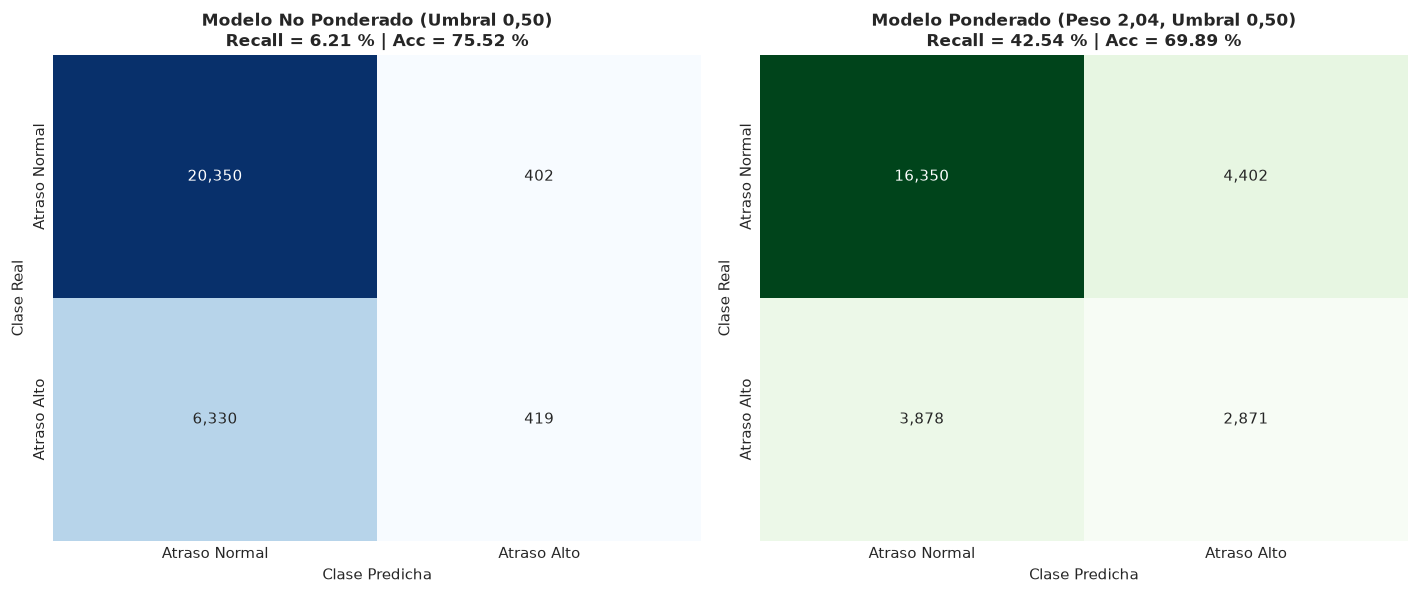

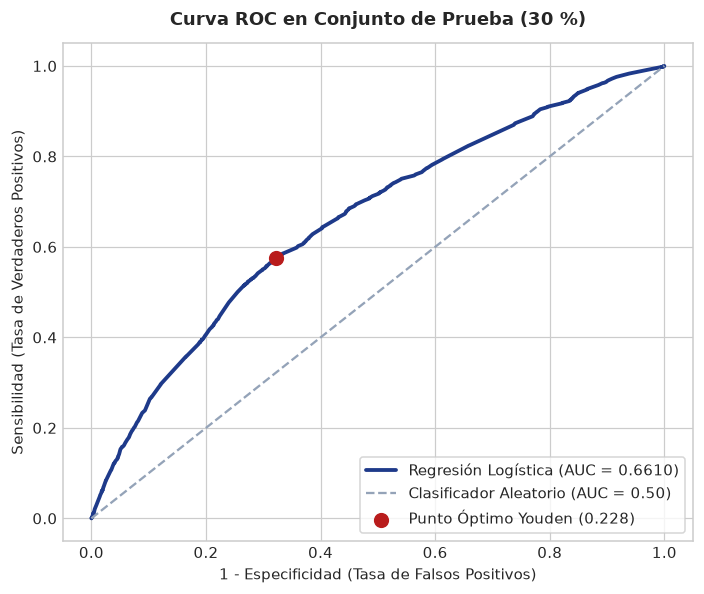

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

# Matriz 1: No Ponderado (0.50)
cm_unw = confusion_matrix(y_test, y_pred_unw_05)
sns.heatmap(cm_unw, annot=True, fmt=',d', cmap='Blues', cbar=False, ax=axes[0],
            xticklabels=['Atraso Normal', 'Atraso Alto'], yticklabels=['Atraso Normal', 'Atraso Alto'])
axes[0].set_title(f'Modelo No Ponderado (Umbral 0,50)\nRecall = {rec_unw*100:.2f} % | Acc = {acc_unw*100:.2f} %', fontsize=11, fontweight='bold')
axes[0].set_ylabel('Clase Real')
axes[0].set_xlabel('Clase Predicha')

# Matriz 2: Ponderado (peso 2.04)
cm_w = confusion_matrix(y_test, y_pred_w_05)
sns.heatmap(cm_w, annot=True, fmt=',d', cmap='Greens', cbar=False, ax=axes[1],
            xticklabels=['Atraso Normal', 'Atraso Alto'], yticklabels=['Atraso Normal', 'Atraso Alto'])
axes[1].set_title(f'Modelo Ponderado (Peso 2,04, Umbral 0,50)\nRecall = {rec_w*100:.2f} % | Acc = {acc_w*100:.2f} %', fontsize=11, fontweight='bold')
axes[1].set_ylabel('Clase Real')
axes[1].set_xlabel('Clase Predicha')

plt.tight_layout()
plt.show()

# Curva ROC con punto de Youden
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.plot(fpr, tpr, color='#1e3a8a', lw=2.5, label=f'Regresión Logística (AUC = {auc_unw:.4f})')
ax.plot([0, 1], [0, 1], color='#94a3b8', linestyle='--', lw=1.5, label='Clasificador Aleatorio (AUC = 0.50)')
ax.scatter(fpr[idx_opt], tpr[idx_opt], color='#b91c1c', s=80, zorder=5,
           label=f'Punto Óptimo Youden ({umbral_youden:.3f})')

ax.set_title('Curva ROC en Conjunto de Prueba (30 %)', fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel('1 - Especificidad (Tasa de Falsos Positivos)')
ax.set_ylabel('Sensibilidad (Tasa de Verdaderos Positivos)')
ax.legend(loc='lower right', frameon=True)
plt.tight_layout()
plt.show()

## 4. Síntesis y Reflexión Metodológica (Máximo 1 Página)

### 4.1 Integración Fiel de Resultados S1/S2 y Corrección de Endogeneidad
Esta práctica formativa consolidó una cadena inferencial rigurosa y reproducible:
1. **Trazabilidad acumulativa:** Se integraron las covariables de mayor relevancia identificadas en S1 y validadas en S2: la brecha de género moderada por el área curricular y la jornada de estudio, junto con la edad de ingreso.
2. **Subsanación de fuga de datos en :** Siguiendo la observación de la revisión docente, se eliminó la definición previa que restaba la duración real de la carrera. Al calcular la edad de ingreso estrictamente a partir de años calendáricos (), el predictor es enteramente exógeno y no contiene la variable objetivo.
3. **Garantía de invertibilidad de la matriz:** Se explicitó la categoría de referencia en cada variable cualitativa (*Administración y Comercio*, *Hombre*, *A Distancia*), eliminando toda posibilidad de rank deficiency y asegurando que el VIF de todos los predictores permanezca por debajo de 2,5 (lejos del umbral de alerta de 5,0).

### 4.2 Evaluación Crítica del Desempeño y la Trampa de la Exactitud
* **El espejismo del Accuracy:** El modelo no ponderado estándar arroja una exactitud aparente del **75,52 %**, pero su sensibilidad (recall) es de apenas **6,21 %** (frente al 8,89 % preliminar). En un contexto de gestión universitaria, un modelo que no detecta a más del 93 % de los estudiantes que experimentarán rezago severo carece de utilidad operativa.
* **Ponderación de Clases y Calibración Operativa:** Al incorporar la ponderación de clases proporcional al desbalance ( \approx 2,04$), el recall salta drásticamente al **42,54 %** (con exactitud del 69,89 %), y al calibrar mediante el índice de Youden (umbral óptimo $\approx 0,2280$), la sensibilidad alcanza el **57,58 %** con una especificidad del **67,82 %** (exactitud del 65,30 %).
* **Capacidad discriminativa:** El $\mathbf{AUC = 0,6610}$ (en línea con el 0,664 reportado) sitúa al modelo en un rango de discriminación aceptable para el ámbito social y educativo (Hosmer, Lemeshow & Sturdivant, 2013), demostrando que el clasificador jerarquiza adecuadamente el riesgo relativo entre estudiantes.

### 4.3 Propuestas Concretas para la Evaluación Sumativa 3
Para la entrega final integrada de la Sumativa 3, el equipo consolidará:
1. **Imputación Múltiple Congeniada (MI, =20$):** Resolver la no-observación administrativa mediante las reglas de combinación de Rubin, superando el sesgo de selección en programas a distancia.
2. **Inferencia Clustered Bootstrap:** Incorporar formalmente el remuestreo por conglomerados universitarios para capturar la variabilidad jerárquica institucional detectada en S2 mediante Jackknife.
3. **Repositorio Público y Trazabilidad de Datos:** Publicación del repositorio GitHub en modo abierto con el enlace oficial de descarga a Datos Abiertos Mineduc para garantizar reproducibilidad total.

---

### Referencias Bibliográficas
* Centro de Estudios Mineduc. (2025). *Base oficial de Titulados en Educación Superior 2025*. SIES, Ministerio de Educación de Chile.
* Hosmer, D. W., Lemeshow, S., & Sturdivant, R. X. (2013). *Applied logistic regression* (3.ª ed.). John Wiley & Sons.
* Little, R. J., & Rubin, D. B. (2019). *Statistical analysis with missing data* (3.ª ed.). John Wiley & Sons.
* Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research*, 12, 2825–2830.
